# Part 3 — Movie Recommendation Patterns
## Person 5: MovieLens — Data Loading, Cleaning, Transactions & EDA

**Goal:** prepare MovieLens data so Person 6 can run Apriori / FP-Growth.

**Outputs of this notebook**
- `movies_clean.csv` — merged & cleaned ratings + movie info
- `basket.pkl` — one-hot transaction matrix (users x movies) for `mlxtend`
- `transactions.csv` — each user's list of watched movies (one row per user)
- `plots/` — all EDA figures (PNG) for Person 7

## 0. Setup

In [3]:
# هنا بنجهز المكتبات ونحط القرارات الأساسية (أقل تقييم 3.5 وأقل مشاهدات 50)
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder

sns.set_theme(style="whitegrid")
os.makedirs("plots", exist_ok=True)

# ---- Decisions (tell Person 6 about these two numbers) ----
RATING_THRESHOLD = 3.5   # a movie counts as "watched/liked" if rating >= 3.5
MIN_MOVIE_VIEWS  = 50    # drop movies watched by fewer than 50 users (keeps Apriori fast)
MIN_BASKET_SIZE  = 2     # a user needs at least 2 movies to form any rule

## 1. Load the data

In [4]:
# بنحمل ملفين الداتا (التقييمات والأفلام) ونطبع حجم كل واحد
# المشروع: الداتا في ../Dataset (لو مش موجود بيدور في نفس الفولدر، زي Colab)
DATA_DIR = "../Dataset" if os.path.exists("../Dataset/ratings.csv") else "."

ratings = pd.read_csv(f"{DATA_DIR}/ratings.csv")
movies  = pd.read_csv(f"{DATA_DIR}/movies.csv")

print("ratings:", ratings.shape)
print("movies :", movies.shape)

ratings: (100836, 4)
movies : (9742, 3)


## 2. Inspect the data

In [5]:
# بنبص على أول صفوف التقييمات ونشوف الأعمدة والأنواع والإحصائيات
print("=== ratings ===")
display(ratings.head())
ratings.info()
display(ratings.describe())

=== ratings ===


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [6]:
# نفس الفحص بس لملف الأفلام
print("=== movies ===")
display(movies.head())
movies.info()

=== movies ===


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB


**Columns**
- `ratings.csv`: `userId` (who), `movieId` (which movie), `rating` (0.5–5.0), `timestamp` (Unix seconds)
- `movies.csv`: `movieId`, `title` (with year), `genres` (pipe-separated)

## 3. Cleaning

### 3.1 Missing values & duplicates

In [7]:
# بنشوف فيه قيم ناقصة أو تكرارات ولا لا (الداتا طلعت نضيفة)
print("Missing values — ratings:\n", ratings.isnull().sum(), "\n")
print("Missing values — movies:\n", movies.isnull().sum(), "\n")

print("Fully duplicated rows in ratings :", ratings.duplicated().sum())
print("Same (user, movie) rated twice   :", ratings.duplicated(["userId", "movieId"]).sum())
print("Fully duplicated rows in movies  :", movies.duplicated().sum())
print("Duplicated titles in movies      :", movies["title"].duplicated().sum())

Missing values — ratings:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64 

Missing values — movies:
 movieId    0
title      0
genres     0
dtype: int64 

Fully duplicated rows in ratings : 0
Same (user, movie) rated twice   : 0
Fully duplicated rows in movies  : 0
Duplicated titles in movies      : 5


In [8]:
# بنشيل التكرارات والقيم الناقصة (مفيش حاجة اتشالت لان الداتا نضيفة)
# Apply the cleaning (no-ops on this dataset, but kept so the pipeline is reusable)
n0 = len(ratings)
ratings = ratings.drop_duplicates()
ratings = ratings.drop_duplicates(subset=["userId", "movieId"], keep="last")
ratings = ratings.dropna()
movies  = movies.drop_duplicates().dropna()
print(f"ratings rows: {n0} -> {len(ratings)}")

ratings rows: 100836 -> 100836


### 3.2 Duplicated titles
A few *different* movies share the same title (different `movieId`). If we use the title as the item name, two movies would be merged into one item. Fix: append the `movieId` to those titles only.

In [9]:
# فيه افلام ليها نفس الاسم، فضفنا رقم الفيلم جنب الاسم عشان ما يتدمجوش
dup_titles = movies[movies["title"].duplicated(keep=False)].sort_values("title")
display(dup_titles)

movies["item"] = movies["title"]
mask = movies["title"].duplicated(keep=False)
movies.loc[mask, "item"] = movies.loc[mask, "title"] + " [id " + movies.loc[mask, "movieId"].astype(str) + "]"

,movieId,title,genres
4169,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller
9106,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller
650,838,Emma (1996),Comedy|Drama|Romance
5601,26958,Emma (1996),Romance
5854,32600,Eros (2004),Drama
9135,147002,Eros (2004),Drama|Romance
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller
9468,168358,Saturn 3 (1980),Sci-Fi|Thriller
5931,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller
6932,64997,War of the Worlds (2005),Action|Sci-Fi


### 3.3 Validate rating range & convert timestamp

In [10]:
# بنتأكد إن التقييمات بين 0.5 و5 ونحول الوقت لتاريخ
print("Rating min/max:", ratings["rating"].min(), ratings["rating"].max())
assert ratings["rating"].between(0.5, 5.0).all(), "Found ratings outside 0.5–5.0!"

ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
print("Date range:", ratings["date"].min().date(), "->", ratings["date"].max().date())

# Movies with no genre
print("Movies with '(no genres listed)':", (movies["genres"] == "(no genres listed)").sum())

Rating min/max: 0.5 5.0
Date range: 1996-03-29 -> 2018-09-24
Movies with '(no genres listed)': 34


### 3.4 Merge ratings with movie info

In [11]:
# بندمج التقييمات مع بيانات الافلام عشان نشوف اسم الفيلم جنب كل تقييم
print("Ratings with a movieId missing from movies.csv:", (~ratings["movieId"].isin(movies["movieId"])).sum())

df = ratings.merge(movies[["movieId", "title", "item", "genres"]], on="movieId", how="inner")
df = df[["userId", "movieId", "title", "item", "genres", "rating", "timestamp", "date"]]
print(df.shape)
df.head()

Ratings with a movieId missing from movies.csv: 0
(100836, 8)


,userId,movieId,title,item,genres,rating,timestamp,date
0,1,1,Toy Story (1995),Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,4.0,964982703,2000-07-30 18:45:03
1,1,3,Grumpier Old Men (1995),Grumpier Old Men (1995),Comedy|Romance,4.0,964981247,2000-07-30 18:20:47
2,1,6,Heat (1995),Heat (1995),Action|Crime|Thriller,4.0,964982224,2000-07-30 18:37:04
3,1,47,Seven (a.k.a. Se7en) (1995),Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.0,964983815,2000-07-30 19:03:35
4,1,50,"Usual Suspects, The (1995)","Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.0,964982931,2000-07-30 18:48:51


In [12]:
# بنحفظ الداتا النضيفة في movies_clean.csv
df.to_csv("movies_clean.csv", index=False)
print("saved movies_clean.csv")

saved movies_clean.csv


### 3.5 Outlier detection (heavy users)
Outliers matter here because a user who rated thousands of movies creates a huge basket and inflates the support of many movie pairs. We detect them with the **IQR rule** on the number of ratings per user.

Q1=35, Q3=168, IQR=133, upper fence=368
Outlier users (> fence): 70 of 610 (11.5%)
They produced 51,613 of 100,836 ratings (51.2%)
Most active user rated 2698 movies


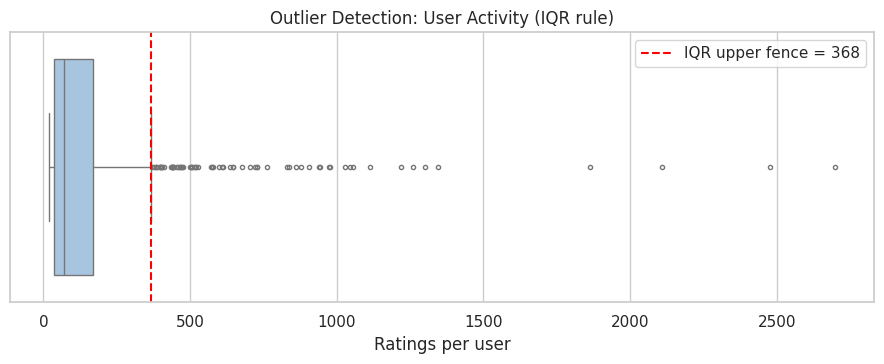

In [13]:
# بندوّر على المستخدمين الغريبين (اللي قيموا أفلام كتير جدا) بقاعدة IQR ونرسمهم
user_activity = ratings.groupby("userId").size()

q1, q3 = user_activity.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outlier_users = user_activity[user_activity > upper_fence]

print(f"Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}, upper fence={upper_fence:.0f}")
print(f"Outlier users (> fence): {len(outlier_users)} of {len(user_activity)} ({len(outlier_users)/len(user_activity):.1%})")
print(f"They produced {outlier_users.sum():,} of {len(ratings):,} ratings ({outlier_users.sum()/len(ratings):.1%})")
print("Most active user rated", user_activity.max(), "movies")

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(x=user_activity, color="#9fc5e8", fliersize=3, ax=ax)
ax.axvline(upper_fence, color="red", linestyle="--", label=f"IQR upper fence = {upper_fence:.0f}")
ax.set_xlabel("Ratings per user")
ax.set_title("Outlier Detection: User Activity (IQR rule)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/08_user_activity_outliers.png", dpi=150)
plt.show()

**Decision: keep the heavy users, but verify the effect (see section 4.4).** They are real viewing behaviour and each is still only one transaction. Their baskets are larger than average though, so we check in 4.4 that the popularity ranking does not depend on them.

## 4. Build the Transactions
**Definition used:** *Transaction* = one user. *Items* = the movies that user watched and liked (`rating >= 3.5`).

Why filter by rating? A low rating means the user watched but disliked it — recommending it alongside other movies would be misleading.

In [14]:
# بناخد التقييمات اللي 3.5 أو أكتر بس، يعني الافلام اللي المستخدم حبها
liked = df[df["rating"] >= RATING_THRESHOLD]
print(f"Ratings kept (>= {RATING_THRESHOLD}): {len(liked)} of {len(df)}  ({len(liked)/len(df):.1%})")
print("Users with at least one liked movie:", liked["userId"].nunique())

Ratings kept (>= 3.5): 61716 of 100836  (61.2%)
Users with at least one liked movie: 609


### 4.1 Filter rare movies
With thousands of movies and only ~600 users, most movies appear in just a handful of baskets. They can never reach a useful `min_support` and only make Apriori slow, so we keep movies watched by at least `MIN_MOVIE_VIEWS` users.

In [15]:
# بنشيل الافلام النادرة (أقل من 50 مشاهد) والمستخدمين اللي عندهم أقل من فيلمين
movie_counts = liked["item"].value_counts()
print("Movies before filter:", len(movie_counts))

popular = movie_counts[movie_counts >= MIN_MOVIE_VIEWS].index
liked_f = liked[liked["item"].isin(popular)]
print(f"Movies after filter (>= {MIN_MOVIE_VIEWS} views): {len(popular)}")

# drop users who now have fewer than MIN_BASKET_SIZE movies
sizes = liked_f.groupby("userId")["item"].nunique()
keep_users = sizes[sizes >= MIN_BASKET_SIZE].index
liked_f = liked_f[liked_f["userId"].isin(keep_users)]
print("Users (transactions) kept:", liked_f["userId"].nunique())

Movies before filter: 7363
Movies after filter (>= 50 views): 242
Users (transactions) kept: 593


### 4.2 Transactions as lists

In [16]:
# بنجمع أفلام كل مستخدم في ليست واحدة (كل مستخدم = Transaction) ونحفظها في transactions.csv
transactions = liked_f.groupby("userId")["item"].apply(lambda s: sorted(set(s)))
display(transactions.head())

# save as CSV (items joined by '|')
pd.DataFrame({"userId": transactions.index,
              "items": transactions.apply(lambda l: "|".join(l)).values}
            ).to_csv("transactions.csv", index=False)
print("saved transactions.csv")

,item
userId,
1,"[Alien (1979), American Beauty (1999), America..."
2,"[Dark Knight Rises, The (2012), Dark Knight, T..."
4,"[12 Angry Men (1957), Airplane! (1980), Aladdi..."
5,"[Aladdin (1992), Babe (1995), Beauty and the B..."
6,"[Aladdin (1992), Apollo 13 (1995), Babe (1995)..."


saved transactions.csv


### 4.3 One-hot matrix (format expected by `mlxtend` Apriori / FP-Growth)

In [17]:
# بنحول الليستات لجدول صح او غلط (One-Hot) ونحفظه في basket.pkl لاحمد
te = TransactionEncoder()
basket = pd.DataFrame(te.fit_transform(transactions.tolist()),
                      columns=te.columns_, index=transactions.index)

print("basket shape (users x movies):", basket.shape)
print("Density (share of True cells):", round(basket.values.mean(), 4))
basket.to_pickle("basket.pkl")
print("saved basket.pkl")

basket shape (users x movies): (593, 242)
Density (share of True cells): 0.1495
saved basket.pkl


### 4.4 Sensitivity check: do heavy users distort the baskets?

In [18]:
# بنقارن أشهر 20 فيلم بالمستخدمين الكتير النشاط وبدونهم، عشان نتأكد إنهم مش بيغيروا النتيجة
heavy_ids = set(outlier_users.index)
is_heavy = basket.index.isin(heavy_ids)
sizes = basket.sum(axis=1)

print(f"Heavy users in basket: {is_heavy.sum()} of {len(basket)}")
print(f"Avg basket size  heavy: {sizes[is_heavy].mean():.1f}  |  others: {sizes[~is_heavy].mean():.1f}")
print(f"Share of all movie-views coming from heavy users: {sizes[is_heavy].sum() / sizes.sum():.1%}")

top_with    = set(basket.sum().sort_values(ascending=False).head(20).index)
top_without = set(basket[~is_heavy].sum().sort_values(ascending=False).head(20).index)
print(f"Top-20 movies shared with / without heavy users: {len(top_with & top_without)} of 20")

Heavy users in basket: 70 of 593
Avg basket size  heavy: 103.2  |  others: 27.2
Share of all movie-views coming from heavy users: 33.7%
Top-20 movies shared with / without heavy users: 18 of 20


**Reading the result:** heavy users do have bigger baskets and contribute about a third of all movie-views, but the top-20 most-watched movies are almost the same with or without them. So we keep them. If Person 6 sees suspiciously strong rules, rerun Apriori on `basket[~is_heavy]` as a robustness check.

## 5. Exploratory Data Analysis
All figures are saved to `plots/` for Person 7.

### 5.1 Top 20 most-watched movies (liked, after cleaning)

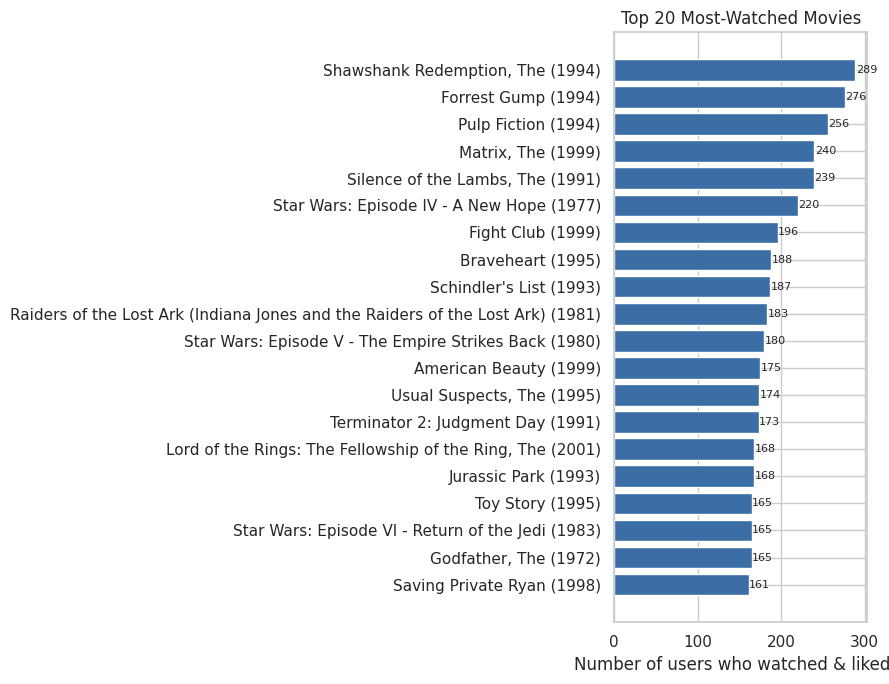

In [19]:
# رسمة أشهر 20 فيلم اتشافوا واتحبوا
top20 = (liked_f["item"].value_counts().head(20)).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top20.index, top20.values, color="#3b6ea5")
ax.set_xlabel("Number of users who watched & liked it")
ax.set_title("Top 20 Most-Watched Movies")
for i, v in enumerate(top20.values):
    ax.text(v + 0.5, i, str(v), va="center", fontsize=8)
plt.tight_layout()
plt.savefig("plots/01_top20_most_watched.png", dpi=150)
plt.show()

### 5.2 Top 20 by *all* ratings (not only liked) — popularity vs. liking

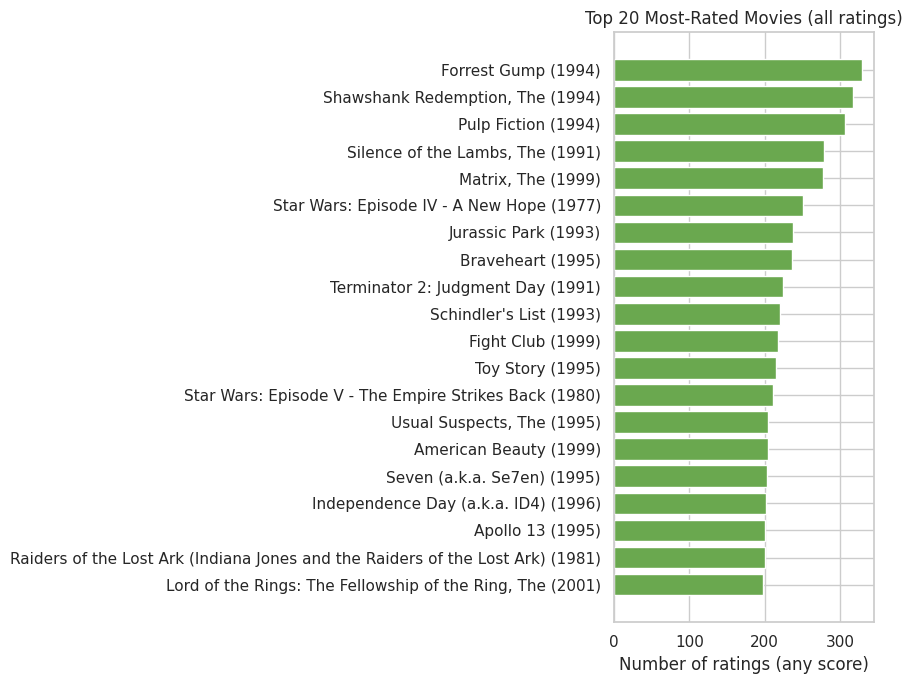

In [20]:
# رسمة أكتر 20 فيلم اتقيّموا (بأي تقييم)
top_all = df["item"].value_counts().head(20).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_all.index, top_all.values, color="#6aa84f")
ax.set_xlabel("Number of ratings (any score)")
ax.set_title("Top 20 Most-Rated Movies (all ratings)")
plt.tight_layout()
plt.savefig("plots/02_top20_most_rated_all.png", dpi=150)
plt.show()

### 5.3 Rating distribution

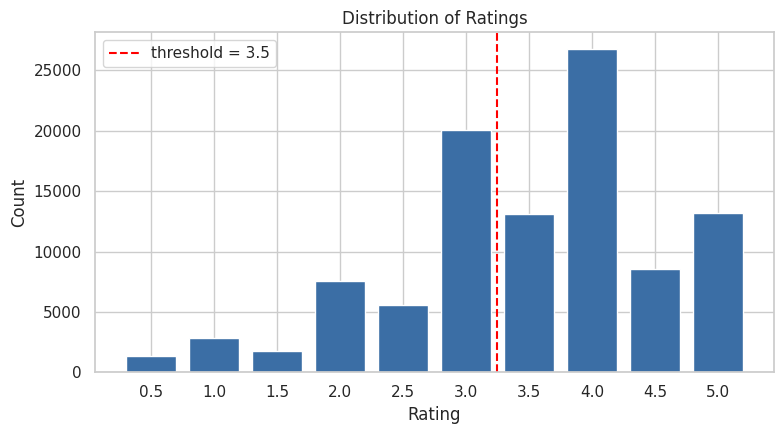

Mean rating: 3.5 | Median: 3.5


In [21]:
# رسمة توزيع التقييمات مع خط الحد 3.5
fig, ax = plt.subplots(figsize=(8, 4.5))
counts = df["rating"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color="#3b6ea5")
ax.axvline(x=list(counts.index).index(RATING_THRESHOLD) - 0.5, color="red", linestyle="--", label=f"threshold = {RATING_THRESHOLD}")
ax.set_xlabel("Rating"); ax.set_ylabel("Count")
ax.set_title("Distribution of Ratings")
ax.legend()
plt.tight_layout()
plt.savefig("plots/03_rating_distribution.png", dpi=150)
plt.show()
print("Mean rating:", round(df["rating"].mean(), 2), "| Median:", df["rating"].median())

### 5.4 Transaction size (movies per user)

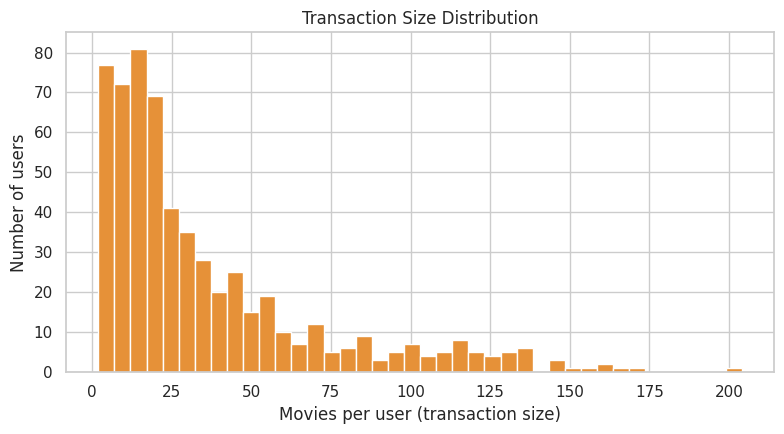

count    593.0
mean      36.2
std       35.6
min        2.0
25%       12.0
50%       22.0
75%       46.0
max      204.0
dtype: float64


In [22]:
# رسمة بتوضح كل مستخدم شاف كام فيلم (حجم الـ Transaction)
basket_sizes = basket.sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(basket_sizes, bins=40, color="#e69138", edgecolor="white")
ax.set_xlabel("Movies per user (transaction size)")
ax.set_ylabel("Number of users")
ax.set_title("Transaction Size Distribution")
plt.tight_layout()
plt.savefig("plots/04_transaction_size_distribution.png", dpi=150)
plt.show()
print(basket_sizes.describe().round(1))

### 5.5 Views per movie (long tail)

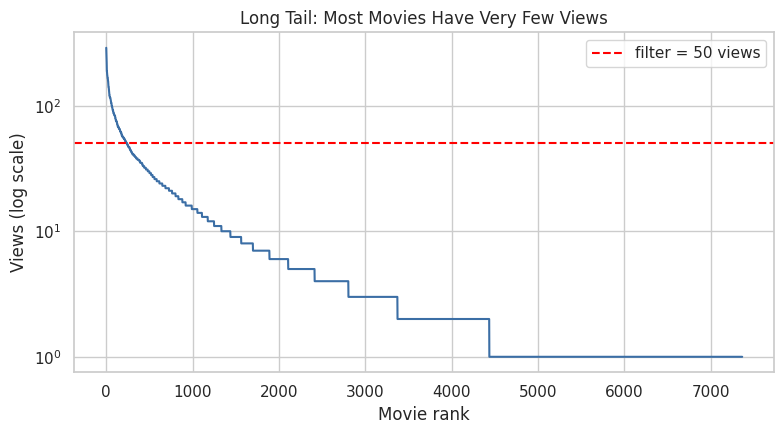

In [23]:
# رسمة الذيل الطويل: أغلب الأفلام مشاهداتها قليلة جدا
all_counts = liked["item"].value_counts().values

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(all_counts) + 1), all_counts, color="#3b6ea5")
ax.axhline(MIN_MOVIE_VIEWS, color="red", linestyle="--", label=f"filter = {MIN_MOVIE_VIEWS} views")
ax.set_yscale("log")
ax.set_xlabel("Movie rank"); ax.set_ylabel("Views (log scale)")
ax.set_title("Long Tail: Most Movies Have Very Few Views")
ax.legend()
plt.tight_layout()
plt.savefig("plots/05_long_tail_views.png", dpi=150)
plt.show()

### 5.6 Genre distribution

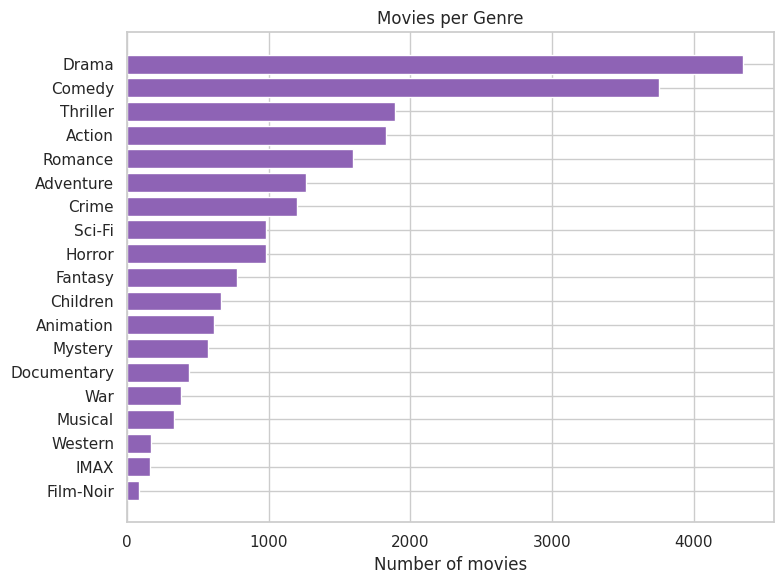

In [24]:
# رسمة عدد الأفلام في كل نوع (Genre)
genre_counts = (movies.loc[movies["movieId"].isin(df["movieId"]), "genres"]
                .str.split("|").explode().value_counts())
genre_counts = genre_counts.drop("(no genres listed)", errors="ignore").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(genre_counts.index, genre_counts.values, color="#8e63b5")
ax.set_xlabel("Number of movies")
ax.set_title("Movies per Genre")
plt.tight_layout()
plt.savefig("plots/06_genre_distribution.png", dpi=150)
plt.show()

### 5.7 Ratings activity over time

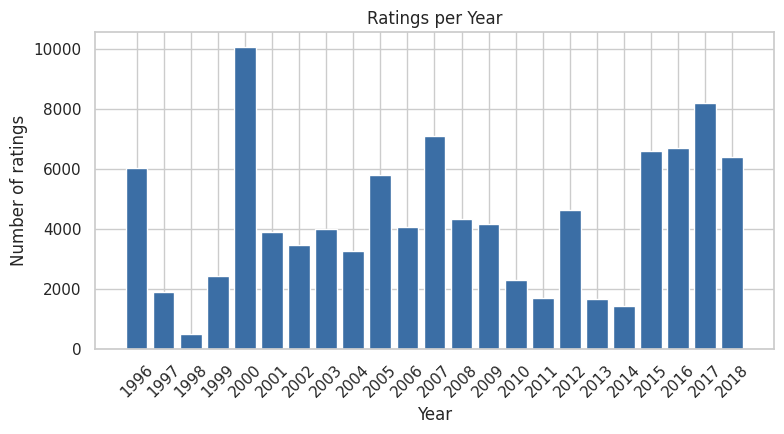

In [25]:
# رسمة عدد التقييمات في كل سنة
per_year = df.groupby(df["date"].dt.year).size()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(per_year.index.astype(str), per_year.values, color="#3b6ea5")
ax.set_xlabel("Year"); ax.set_ylabel("Number of ratings")
ax.set_title("Ratings per Year")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("plots/07_ratings_per_year.png", dpi=150)
plt.show()

## 6. Summary (hand-off notes)

In [26]:
#ملخص الأرقام النهائية
print("=== SUMMARY ===")
print(f"Raw ratings           : {len(ratings):,}")
print(f"Users / Movies (raw)  : {ratings['userId'].nunique()} / {ratings['movieId'].nunique()}")
print(f"'Watched' definition  : rating >= {RATING_THRESHOLD}")
print(f"Min views per movie   : {MIN_MOVIE_VIEWS}")
print(f"Final transactions    : {basket.shape[0]} users")
print(f"Final items           : {basket.shape[1]} movies")
print(f"Avg movies per user   : {basket.sum(axis=1).mean():.1f}")
print("Top 5 movies          :", list(liked_f['item'].value_counts().head(5).index))

=== SUMMARY ===
Raw ratings           : 100,836
Users / Movies (raw)  : 610 / 9724
'Watched' definition  : rating >= 3.5
Min views per movie   : 50
Final transactions    : 593 users
Final items           : 242 movies
Avg movies per user   : 36.2
Top 5 movies          : ['Shawshank Redemption, The (1994)', 'Forrest Gump (1994)', 'Pulp Fiction (1994)', 'Matrix, The (1999)', 'Silence of the Lambs, The (1991)']


### Notes for teammates
- **Person 6:** load with `basket = pd.read_pickle("basket.pkl")`, then `apriori(basket, min_support=..., use_colnames=True)`. Because every movie has >= 50 viewers among ~600 users, the smallest meaningful `min_support` is about 0.08; start around 0.10–0.20 and lower it if you get too few itemsets.
- **Person 7:** figures are in `plots/`.
- **Person 8:** the whole pipeline runs top-to-bottom from `movies.csv` + `ratings.csv`.